# Exploratory Data Analysis: Credit Card Fraud Detection

**Dataset:** data/raw/creditcard.csv (Kaggle Credit Card Fraud Detection).
**Goal:** understand class imbalance, temporal patterns, and feature structure before modelling.

Key findings that shaped the pipeline:
1. **Severe class imbalance** (~0.17%) -> PR-AUC + scale_pos_weight.
2. **Temporal ordering** -> chronological train/val/test split (no leakage).
3. **Skewed Amount** -> log1p transform.
4. **Circadian pattern** -> Hour_Sin / Hour_Cos features.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path('..') / 'data' / 'raw' / 'creditcard.csv'
print('Data path:', DATA_PATH)
df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
print('Columns:', list(df.columns))


Data path: ../data/raw/creditcard.csv


Dataset shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [2]:
print('Total missing values:', int(df.isna().sum().sum()))
print('Dtype counts:', df.dtypes.value_counts().to_dict())
print('Shape:', df.shape)
display(df.describe().T.head(8))


Total missing values: 0
Dtype counts: {dtype('float64'): 30, dtype('int64'): 1}
Shape: (284807, 31)


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494


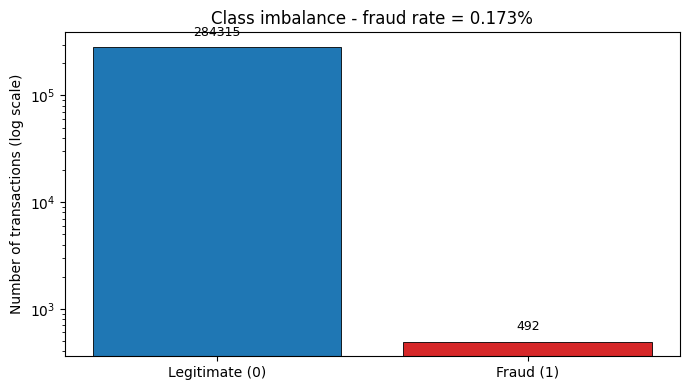

Legitimate: 284315 | Fraud: 492 | Positive rate: 0.1727%
Imbalance scale factor: 577.9x


In [3]:
class_counts = df['Class'].value_counts().sort_index()
fraud_rate = class_counts[1] / len(df) * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Legitimate (0)', 'Fraud (1)'], class_counts.values,
              color=['#1f77b4', '#d62728'], edgecolor='black', linewidth=0.6)
ax.set_yscale('log')
ax.set_ylabel('Number of transactions (log scale)')
ax.set_title('Class imbalance - fraud rate = %.3f%%' % fraud_rate)
for bar, v in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v * 1.2, '%d' % v,
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print('Legitimate: %d | Fraud: %d | Positive rate: %.4f%%'
      % (class_counts[0], class_counts[1], fraud_rate))
print('Imbalance scale factor: %.1fx' % (class_counts[0] / class_counts[1]))


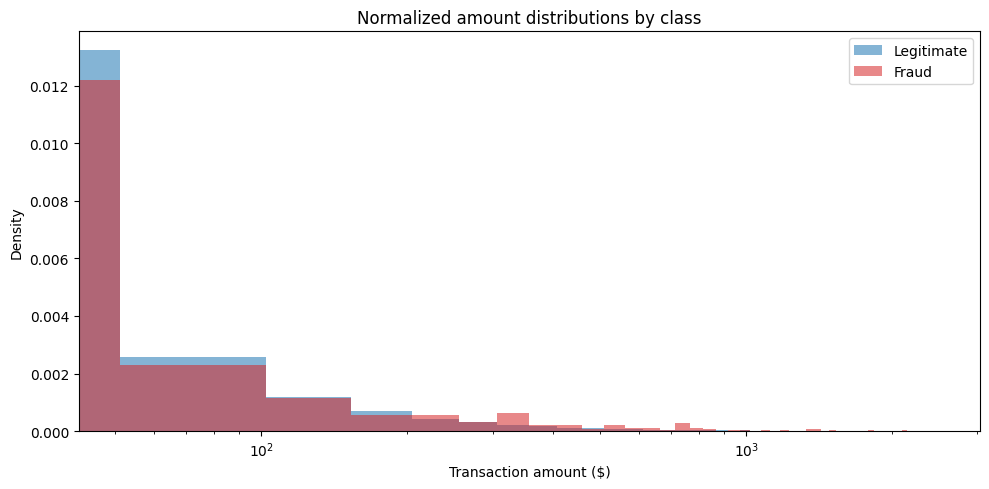

Observation: fraud skews toward a heavy tail of larger amounts; a log transform stabilises it.


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 2500, 50)
ax.hist(df[df['Class'] == 0]['Amount'], bins=bins, alpha=0.55,
        label='Legitimate', density=True, color='#1f77b4')
ax.hist(df[df['Class'] == 1]['Amount'], bins=bins, alpha=0.55,
        label='Fraud', density=True, color='#d62728')
ax.set_xscale('log')
ax.set_xlabel('Transaction amount ($)')
ax.set_ylabel('Density')
ax.set_title('Normalized amount distributions by class')
ax.legend()
plt.tight_layout()
plt.show()
print('Observation: fraud skews toward a heavy tail of larger amounts; a log transform stabilises it.')


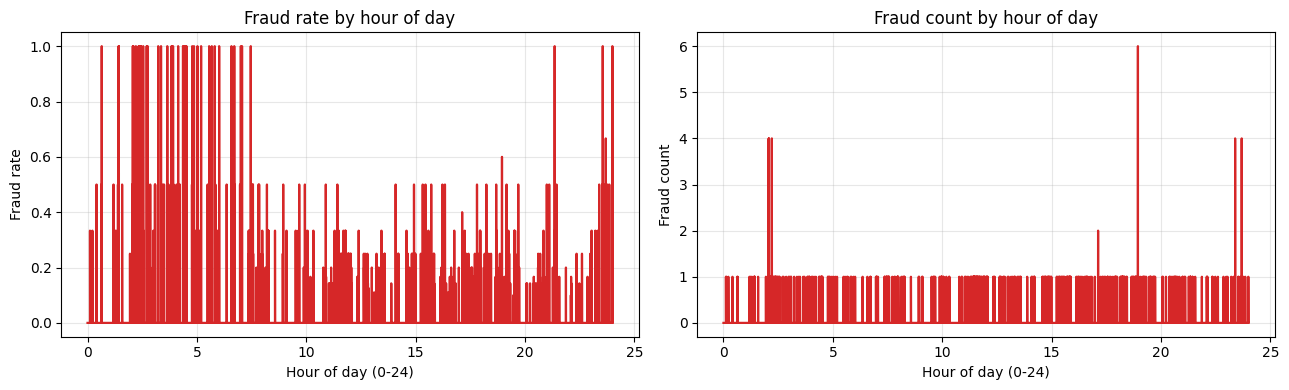

Observation: fraud activity varies by hour; motivates cyclical hour features.


In [5]:
df_sorted = df.sort_values('Time')
df_sorted['Hour'] = (df_sorted['Time'] % 86400) / 3600
hourly = df_sorted.groupby('Hour').agg(fraud_count=('Class', 'sum'), total=('Class', 'count'))
hourly['fraud_rate'] = hourly['fraud_count'] / hourly['total']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hourly.index, hourly['fraud_rate'], color='#d62728', linewidth=1.6)
axes[0].set_xlabel('Hour of day (0-24)')
axes[0].set_ylabel('Fraud rate')
axes[0].set_title('Fraud rate by hour of day')
axes[0].grid(alpha=0.3)
axes[1].plot(hourly.index, hourly['fraud_count'], color='#d62728', linewidth=1.6)
axes[1].set_xlabel('Hour of day (0-24)')
axes[1].set_ylabel('Fraud count')
axes[1].set_title('Fraud count by hour of day')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print('Observation: fraud activity varies by hour; motivates cyclical hour features.')


Top |correlation| with Class:
Class    1.000
V17      0.326
V14      0.303
V12      0.261
V10      0.217
V16      0.197
V3       0.193
V7       0.187


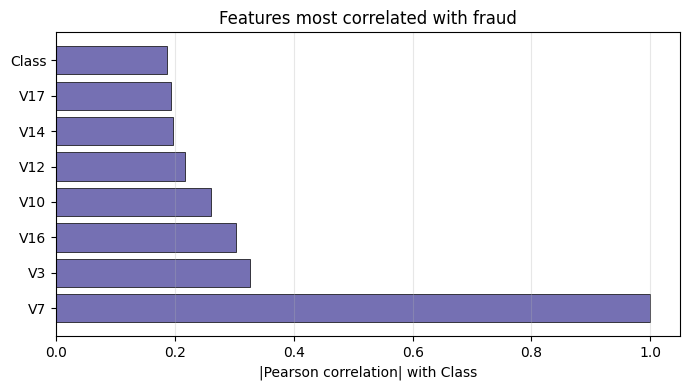

In [6]:
df = df.assign(Log_Amount=np.log1p(df['Amount']))
corrs = df.corr()['Class'].abs().sort_values(ascending=False)
top_feats = corrs.head(8).index.tolist()
print('Top |correlation| with Class:')
print(corrs.head(8).round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top_feats[::-1], corrs.loc[top_feats[::-1]].values[::-1],
        color='#7570b3', edgecolor='black', linewidth=0.5)
ax.set_xlabel('|Pearson correlation| with Class')
ax.set_title('Features most correlated with fraud')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


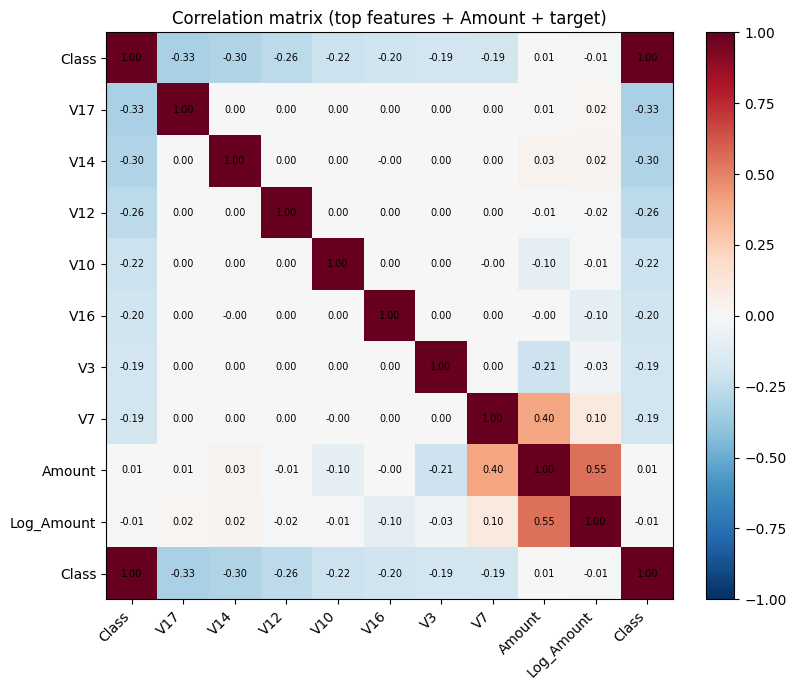

Observation: PCA features are already decorrelated; log1p captures the amount signal without redundancy.


In [7]:
cols = top_feats + ['Amount', 'Log_Amount', 'Class']
corr_mat = df[cols].corr()
fig, ax = plt.subplots(figsize=(9,7))
im = ax.imshow(corr_mat, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(cols)))
ax.set_yticks(np.arange(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, '%.2f' % corr_mat.iloc[i, j], ha='center', va='center', fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Correlation matrix (top features + Amount + target)')
plt.tight_layout()
plt.show()
print('Observation: PCA features are already decorrelated; log1p captures the amount signal without redundancy.')


In [8]:
learnings = [
    ('Severe imbalance', 'Fraud is ~0.17% of transactions. We optimise PR-AUC and train XGBoost with scale_pos_weight from the training set only.'),
    ('Temporal order', 'Fraud patterns drift over time. Chronological splits ensure the model never sees future data during training.'),
    ('Skewed amounts', 'Amount is heavy-tailed. Log1p is applied in the feature pipeline.'),
    ('Circadian effect', 'Fraud rate varies by hour. Hour_Sin/Hour_Cos capture daily cycles.'),
    ('Decorrelated features', 'PCA features show low mutual correlation, so no aggressive feature selection is required.'),
]
for title, note in learnings:
    print()
    print('**' + title + '**')
    print('  - ' + note)



**Severe imbalance**
  - Fraud is ~0.17% of transactions. We optimise PR-AUC and train XGBoost with scale_pos_weight from the training set only.

**Temporal order**
  - Fraud patterns drift over time. Chronological splits ensure the model never sees future data during training.

**Skewed amounts**
  - Amount is heavy-tailed. Log1p is applied in the feature pipeline.

**Circadian effect**
  - Fraud rate varies by hour. Hour_Sin/Hour_Cos capture daily cycles.

**Decorrelated features**
  - PCA features show low mutual correlation, so no aggressive feature selection is required.
